In [6]:
#HELPER
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df_fabrica = pd.read_csv('steel_industry_data.csv')
#  ¡ESTA ES LA PARTE CLAVE! Quitamos los espacios extra de los nombres de columnas
df_fabrica.columns = df_fabrica.columns.str.strip()
df_fabrica

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 0:15,3.17,2.95,0.00,0.0,73.21,100.00,900,Weekday,Monday,Light_Load
1,01/01/2018 0:30,4.00,4.46,0.00,0.0,66.77,100.00,1800,Weekday,Monday,Light_Load
2,01/01/2018 0:45,3.24,3.28,0.00,0.0,70.28,100.00,2700,Weekday,Monday,Light_Load
3,01/01/2018 1:00,3.31,3.56,0.00,0.0,68.09,100.00,3600,Weekday,Monday,Light_Load
4,01/01/2018 1:15,3.82,4.50,0.00,0.0,64.72,100.00,4500,Weekday,Monday,Light_Load
...,...,...,...,...,...,...,...,...,...,...,...
35035,31/12/2018 23:00,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,31/12/2018 23:15,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load


In [3]:
df_fabrica.isnull().sum()

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

<Axes: >

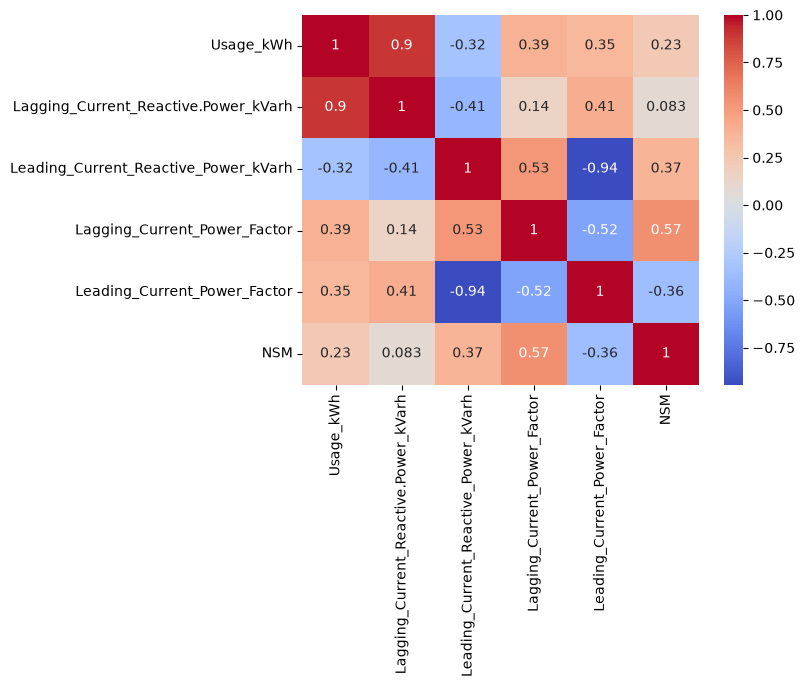

In [8]:
#Para buscar correlaciones entre los datos: 
Df = df_fabrica.drop(columns=["CO2(tCO2)"])
Df.corr(numeric_only=True)
sns.heatmap(Df.corr(numeric_only=True),annot=True,cmap='coolwarm')

<Axes: xlabel='Usage_kWh', ylabel='Lagging_Current_Reactive.Power_kVarh'>

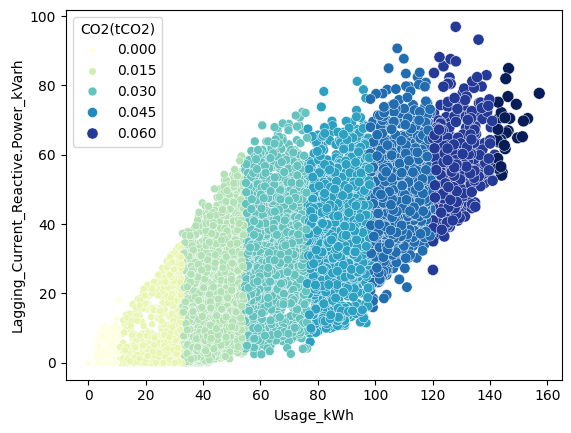

In [5]:
#Dispersion
sns.scatterplot(x="Usage_kWh",y="Lagging_Current_Reactive.Power_kVarh",data=df_fabrica,hue='CO2(tCO2)',size="CO2(tCO2)",palette="YlGnBu")

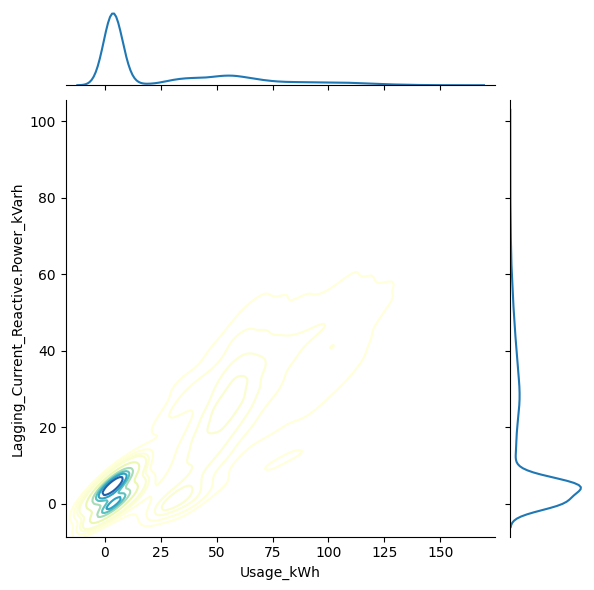

In [6]:
sns.jointplot(x="Usage_kWh",y="Lagging_Current_Reactive.Power_kVarh",data=df_fabrica,kind='kde', palette='YlGnBu', cmap='YlGnBu')

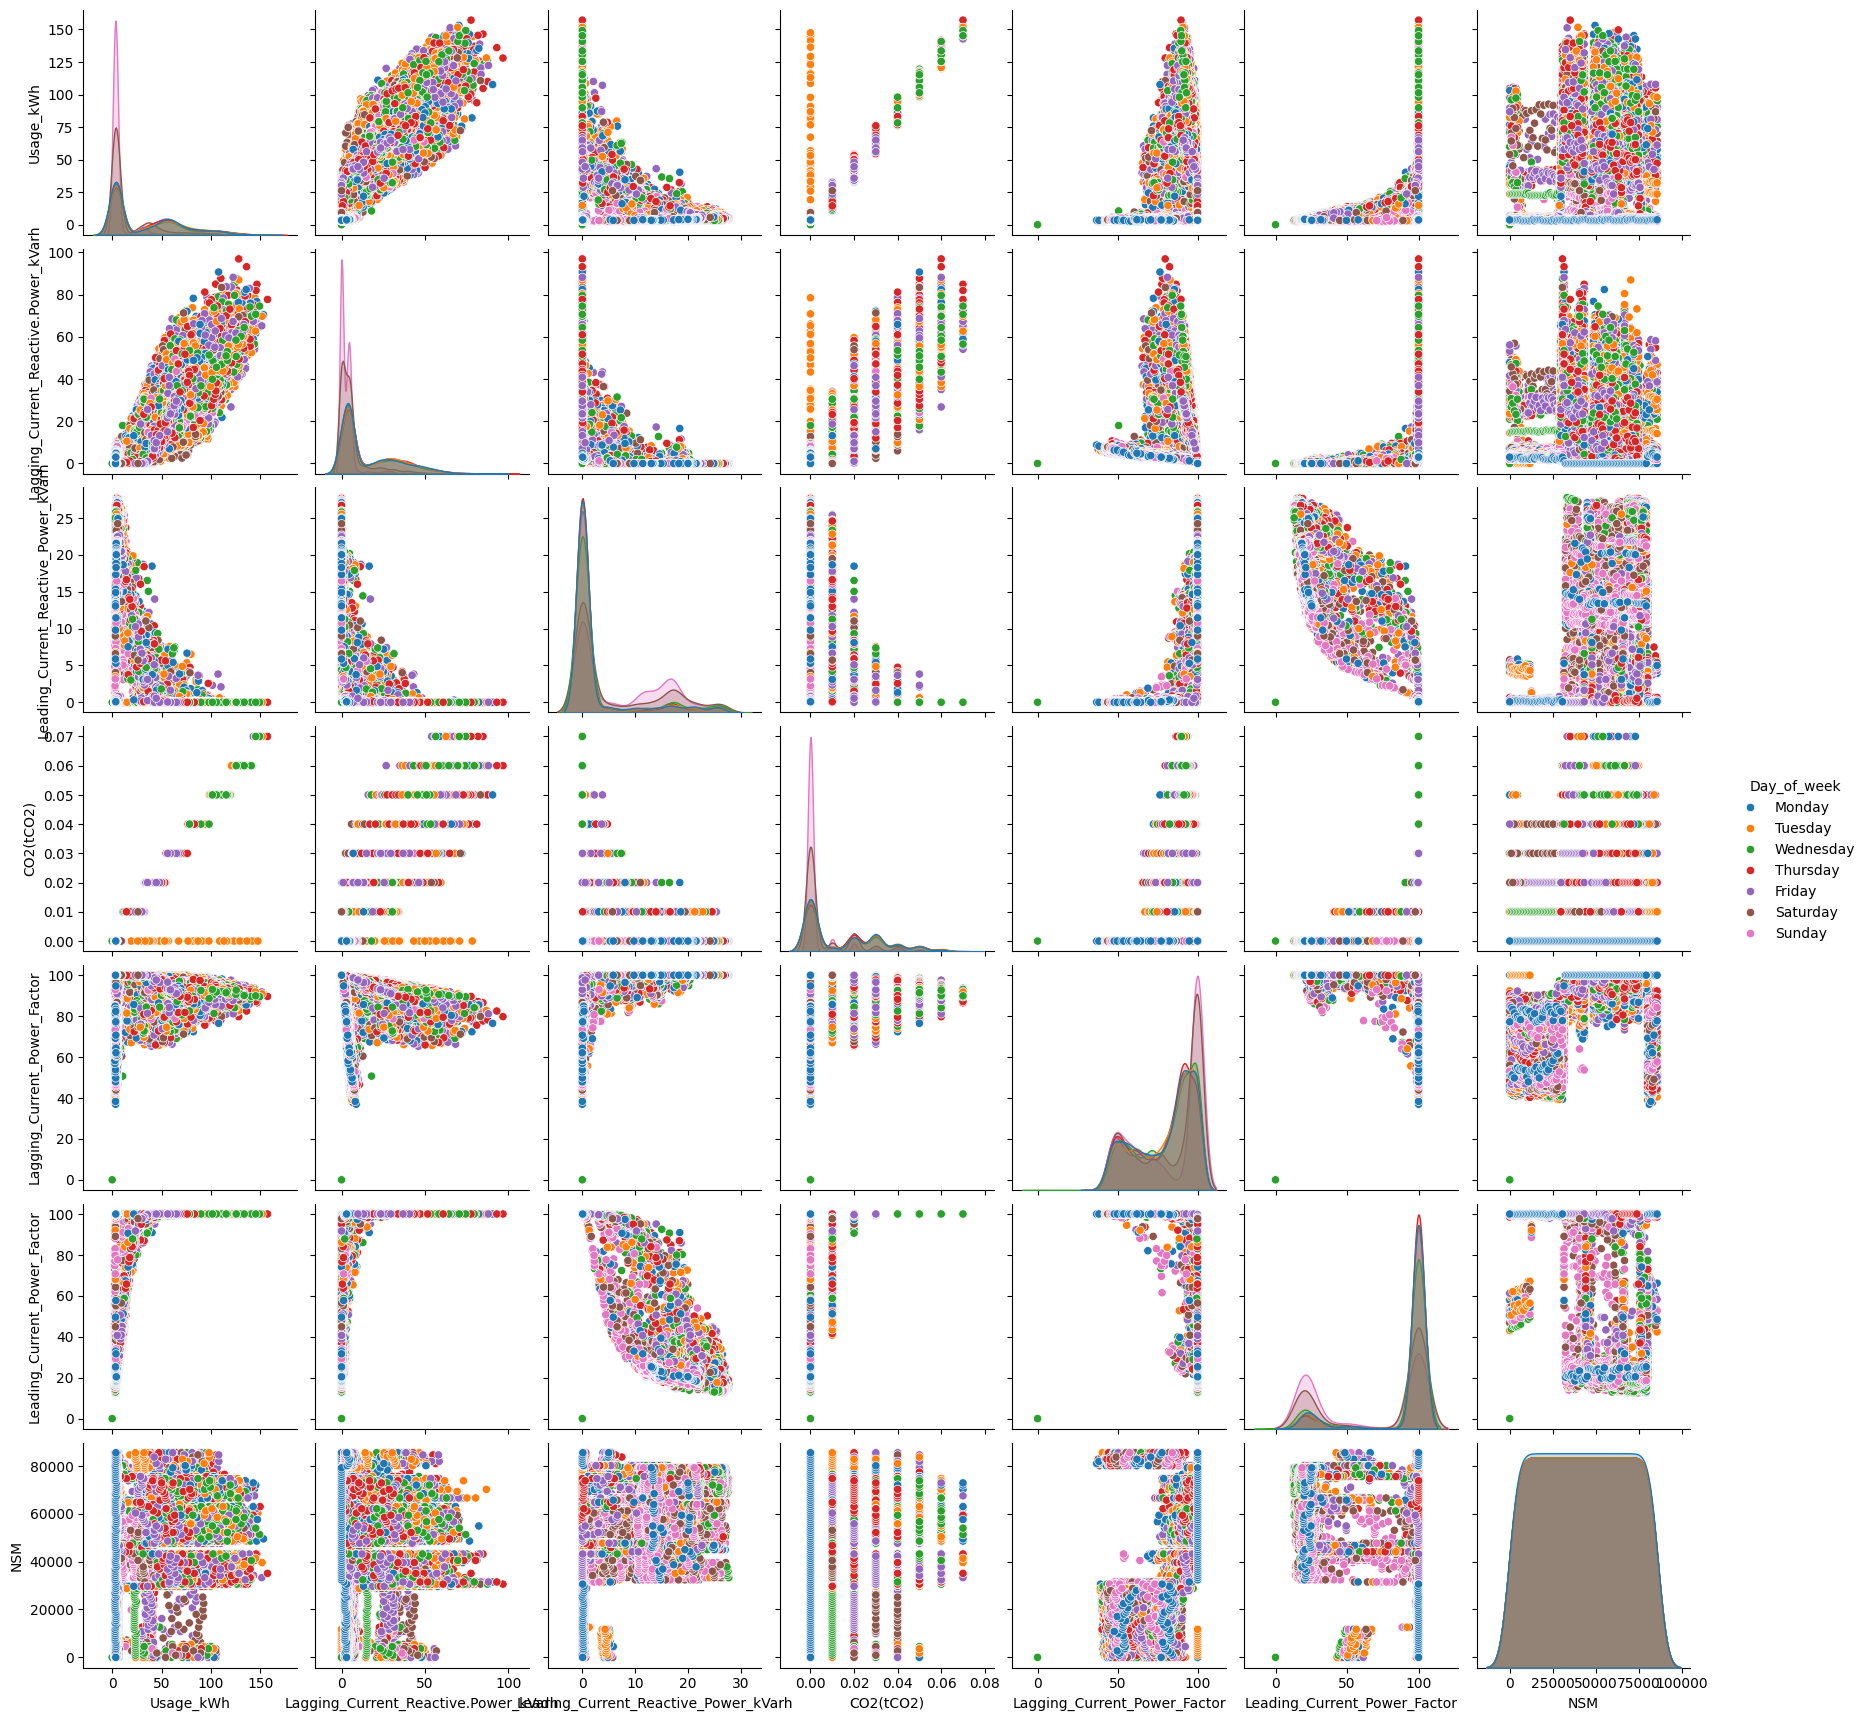

In [7]:
sns.pairplot(df_fabrica.select_dtypes(['number']).join(df_fabrica['Day_of_week']),hue='Day_of_week')

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression


# Variable independiente
X = df_fabrica[["NSM"]]

# Variable dependiente
y = df_fabrica["Usage_kWh"]

# Generar términos polinómicos de grado 2
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

# Ajustar el modelo
modelo = LinearRegression()
modelo.fit(X_poly, y)

# Mostrar coeficientes
print("Intercepto:", modelo.intercept_)
print("Coeficientes:", modelo.coef_)
print("R²:", modelo.score(X_poly, y))

Intercepto: -16.420995620106037
Coeficientes: [ 2.46769345e-03 -2.51823304e-08]
R²: 0.23047236020635864


¿Qué hace cada parte?
- PolynomialFeatures(degree=2): transforma NSM en dos variables: \(NSM\) y \(NSM^2\).
- LinearRegression(): ajusta los coeficientes del modelo.
- modelo.intercept_: devuelve \(\beta_0\).
- modelo.coef_: devuelve \(\beta_1\) y \(\beta_2\), en ese orden.
- modelo.score(...): calcula el coeficiente de determinación \(R^2\).
El modelo resultante tiene esta forma:
\[
Usage\_kWh=\beta_0+\beta_1(NSM)+\beta_2(NSM^2)
\]

Importante: en este código, el \(R^2\) se calcula sobre los mismos datos utilizados para ajustar el modelo. Es útil para evaluar el ajuste sobre el dataset, pero no mide por sí solo qué tan bien predice datos nuevos.

In [15]:
from sklearn.linear_model import LinearRegression

# Variable independiente
X_lineal = df_fabrica[["NSM"]]

# Variable dependiente
y = df_fabrica["Usage_kWh"]

# Ajustar modelo lineal
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_lineal, y)

# Mostrar resultados
print("Intercepto:", modelo_lineal.intercept_)
print("Pendiente:", modelo_lineal.coef_[0])
print("R²:", modelo_lineal.score(X_lineal, y))

Intercepto: 13.937562820693886
Pendiente: 0.00031460420088846587
R²: 0.055042005659105


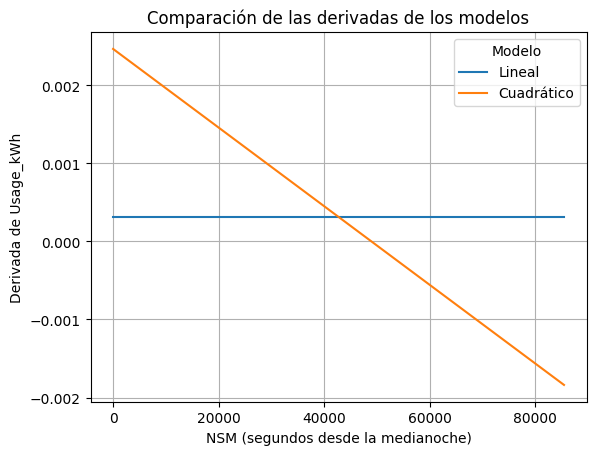

In [16]:


# Valores de NSM ordenados para dibujar las curvas
x = np.linspace(df_fabrica["NSM"].min(), df_fabrica["NSM"].max(), 500)

# Derivada del modelo lineal: f'(x) = b1
derivada_lineal = np.full_like(x, modelo_lineal.coef_[0])

# Derivada del modelo cuadrático: f'(x) = b1 + 2*b2*x
derivada_cuadratica = modelo.coef_[0] + 2 * modelo.coef_[1] * x

# Preparar los datos para seaborn
df_derivadas = pd.DataFrame({
    "NSM": np.concatenate([x, x]),
    "Derivada": np.concatenate([derivada_lineal, derivada_cuadratica]),
    "Modelo": ["Lineal"] * len(x) + ["Cuadrático"] * len(x)
})

# Graficar
sns.lineplot(
    data=df_derivadas,
    x="NSM",
    y="Derivada",
    hue="Modelo"
)

plt.xlabel("NSM (segundos desde la medianoche)")
plt.ylabel("Derivada de Usage_kWh")
plt.title("Comparación de las derivadas de los modelos")
plt.grid(True)
plt.show()

Modelo lineal: una recta horizontal, porque su derivada es constante.
Modelo cuadrático: una recta inclinada, porque su derivada depende de NSM.

• Estimar la ecuación de la regresión múltiple de la sección B.5 por el método del descenso del gradiente, con la regla de actualización:
b⁽ᵏ⁺¹⁾ = b⁽ᵏ⁾ − α · ∇f(b⁽ᵏ⁾)
donde α es la tasa de aprendizaje y k el número de iteración
• Justificar en dos líneas por qué el algoritmo avanza en la dirección opuesta al gradiente.
El vector gradiente señala matemáticamente la dirección en la que el error aumenta más rápido. Moverse en sentido contrario asegura ir bajando por la superficie hasta minimizar el error.
• Ejecutarlo con tres tasas de aprendizaje: una demasiado pequeña, una adecuada y una que provoque divergencia. Graficar f en función del número de iteración para las tres en un mismo par de ejes y explicar qué ocurre en cada caso.
• Indicar el criterio de detención utilizado y comparar la solución obtenida con la exacta de mínimos cuadrados.

In [15]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. PREPARAR LOS DATOS DE B.5
# ==========================================

variables = [
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "Lagging_Current_Power_Factor",
    "NSM"
]

X_original = df_fabrica[variables].to_numpy(dtype=float)
y = df_fabrica["Usage_kWh"].to_numpy(dtype=float)

# Estandarizar las variables explicativas
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_original)

# Agregar intercepto
m = len(y)
X = np.column_stack((np.ones(m), X_escalado))

# ==========================================
# 2. FUNCION DE COSTO Y GRADIENTE
# ==========================================

def f(b):
    errores = X @ b - y
    return np.sum(errores**2) / (2 * m)

def gradiente(b):
    return X.T @ (X @ b - y) / m

# ==========================================
# 3. TASAS DE APRENDIZAJE
# ==========================================

L = np.linalg.eigvalsh(X.T @ X / m).max()

tasas = {
    "Muy pequeña": 0.01 / L,
    "Adecuada": 1.0 / L,
    "Divergente": 2.1 / L
}

# ==========================================
# 4. DESCENSO DEL GRADIENTE
# ==========================================

def descenso_gradiente(alpha, max_iter=300, tol=1e-6):
    b = np.zeros(X.shape[1])
    historial = [f(b)]

    for k in range(max_iter):
        g = gradiente(b)

        if np.linalg.norm(g) < tol:
            break

        b = b - alpha * g
        costo = f(b)
        historial.append(costo)

        if not np.isfinite(costo) or costo > 1e100:
            break

    return b, historial, k + 1

# ==========================================
# 5. EJECUTAR LOS TRES CASOS
# ==========================================

resultados = {}

for nombre, alpha in tasas.items():
    b, historial, iteraciones = descenso_gradiente(alpha)

    resultados[nombre] = {
        "b": b,
        "historial": historial,
        "iteraciones": iteraciones
    }

    print(f"\n{nombre}")
    print("Costo final:", historial[-1])
    print("Iteraciones:", iteraciones)

# ==========================================
# 6. SOLUCION EXACTA POR ECUACIONES NORMALES
# ==========================================

# Se resuelve en la escala estandarizada
b_exacta_escalado = np.linalg.lstsq(X, y, rcond=None)[0]
print("Costo mínimo por mínimos cuadrados:", f(b_exacta_escalado))

for nombre, resultado in resultados.items():
    print(
        nombre,
        "Costo final:", resultado["historial"][-1],
        "Diferencia con el mínimo:",
        resultado["historial"][-1] - f(b_exacta_escalado)
    )

# Convertir coeficientes a la escala original
b_exacta = b_exacta_escalado.copy()
b_exacta[1:] = b_exacta_escalado[1:] / scaler.scale_
b_exacta[0] = (
    b_exacta_escalado[0]
    - np.sum(b_exacta_escalado[1:] * scaler.mean_ / scaler.scale_)
)

print("\nCoeficientes exactos en escala original:")
print("Intercepto:", b_exacta[0])

for nombre, coef in zip(variables, b_exacta[1:]):
    print(f"{nombre}: {coef}")

# ==========================================
# 7. GRAFICAR LOS COSTOS
# ==========================================

fig = go.Figure()

for nombre, resultado in resultados.items():
    fig.add_trace(go.Scatter(
        x=list(range(len(resultado["historial"]))),
        y=resultado["historial"],
        mode="lines",
        name=nombre
    ))

costo_exacto = f(b_exacta_escalado)

fig.add_hline(
    y=costo_exacto,
    line_dash="dash",
    annotation_text="Mínimos cuadrados"
)

fig.update_layout(
    title="Descenso del gradiente - Regresión múltiple B.5",
    xaxis_title="Iteración",
    yaxis_title="Función de costo f(b)",
    yaxis_type="log",
    template="plotly_white"
)

import plotly.io as pio

fig.write_html("grafico_descenso.html", auto_open=True)



Muy pequeña
Costo final: 89.22901181928725
Iteraciones: 300

Adecuada
Costo final: 56.37999915894267
Iteraciones: 95

Divergente
Costo final: 1.5102064739139803e+25
Iteraciones: 300
Costo mínimo por mínimos cuadrados: 56.3799991589411
Muy pequeña Costo final: 89.22901181928725 Diferencia con el mínimo: 32.849012660346155
Adecuada Costo final: 56.37999915894267 Diferencia con el mínimo: 1.5702994460298214e-12
Divergente Costo final: 1.5102064739139803e+25 Diferencia con el mínimo: 1.5102064739139803e+25

Coeficientes exactos en escala original:
Intercepto: -45.056510813928014
Lagging_Current_Reactive.Power_kVarh: 1.513735847899265
Leading_Current_Reactive_Power_kVarh: -1.1016812309310793
Lagging_Current_Power_Factor: 0.6717641048567716
NSM: 6.65820228593813e-05


Tasa pequeña: la función de costo disminuye lentamente porque los pasos son reducidos.
Tasa adecuada: converge hacia el mínimo de la función de costo.
Tasa divergente: los pasos son demasiado grandes y el costo aumenta o se vuelve numéricamente inestable.
Criterio de detención: norma del gradiente menor que \(10^{-6}\), o alcanzar el máximo de 300 iteraciones.
Comparación: comparar los coeficientes obtenidos por descenso del gradiente con los de mínimos cuadrados y verificar si ambos alcanzan costos similares.